# DEEP REINFORCEMENT LEARNING BOOTCAMP, 2026
## Section 1 Assignment: Mission Debrief, Rebooting Mary's Core

This assignment closes Section 1: you recalibrate Mary's learning core across four flight systems, using only tabular methods from Days 1-4.
The situation: Mary's learning circuits are back online, but she needs recalibration. Work through the four systems below, then answer the wrap-up questions for her logbook.

# Part 1: Fuel Station Selection (Bandits), 15 pts

#### Mary must choose among refueling stations that each give a noisy fuel yield with an unknown mean. You compare three exploration strategies.
    
    1. Build a 10-armed bandit environment with Gaussian rewards and fixed random means. (3 pts)
    2. Implement ε-greedy with ε = 0.01 and ε = 0.1. (5 pts)
    3. Implement UCB. (3 pts)
    4. Run each agent for 1,000 steps, averaged over 100 runs, and plot the average reward for all three. (4 pts)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Experiment settings
N_ARMS = 10
N_STEPS = 1000
N_RUNS = 100

EPSILONS = [0.01, 0.1]
UCB_C = 2.0

In [ ]:
# Building 10-armed Gaussian bandit environment

class GaussianBandit:
    def __init__(self, n_arms=10, rng=None):
        self.n_arms = n_arms
        self.rng = rng if rng is not None else np.random.default_rng()

        # True mean reward of each station
        self.q_true = self.rng.normal(
            loc=0.0, scale=1.0, size=n_arms
        )

    def step(self, action):
        # Reward is drawn from N(q_true[action], 1)
        reward = self.rng.normal(
            loc=self.q_true[action], scale=1.0
        )
        return reward

In [ ]:
# Epsilon-greedy agent

class EpsilonGreedy:
    def __init__(self, n_arms=10, epsilon=0.1):
        self.n_arms = n_arms
        self.epsilon = epsilon

        # Estimated action values
        self.Q = np.zeros(n_arms)

        # Number of times each action was selected
        self.N = np.zeros(n_arms, dtype=int)

    def select_action(self, rng):
        # Explore with probability epsilon
        if rng.random() < self.epsilon:
            return rng.integers(self.n_arms)

        # Exploit: choose randomly among greedy actions
        best_actions = np.flatnonzero(
            self.Q == np.max(self.Q)
        )
        return rng.choice(best_actions)

    def update(self, action, reward):
        self.N[action] += 1

        # Incremental sample-average update
        self.Q[action] += (
            reward - self.Q[action]
        ) / self.N[action]

In [ ]:
# Upper Confidence Bound (UCB) agent

class UCBAgent:
    def __init__(self, n_arms=10, c=2.0):
        self.n_arms = n_arms
        self.c = c

        self.Q = np.zeros(n_arms)
        self.N = np.zeros(n_arms, dtype=int)

    def select_action(self, t, rng):
        # Try every unselected station before applying UCB
        untried_actions = np.flatnonzero(self.N == 0)

        if len(untried_actions) > 0:
            return rng.choice(untried_actions)

        # UCB score = estimated value + exploration bonus
        ucb_scores = self.Q + self.c * np.sqrt(
            2.0 * np.log(t) / self.N
        )

        best_actions = np.flatnonzero(
            np.isclose(ucb_scores, np.max(ucb_scores))
        )

        return rng.choice(best_actions)

    def update(self, action, reward):
        self.N[action] += 1

        # Incremental sample-average update
        self.Q[action] += (
            reward - self.Q[action]
        ) / self.N[action]

In [ ]:
# Run one agent for one independent run

def run_experiment(agent_type, q_true, seed,
                   epsilon=None, c=2.0):

    rng = np.random.default_rng(seed)

    # Each agent receives the same true means for
    # the corresponding independent run.
    bandit = GaussianBandit(N_ARMS, rng)
    bandit.q_true = q_true.copy()

    if agent_type == "epsilon_greedy":
        agent = EpsilonGreedy(
            N_ARMS, epsilon=epsilon
        )
    elif agent_type == "ucb":
        agent = UCBAgent(N_ARMS, c=c)
    else:
        raise ValueError("Unknown agent type")

    rewards = np.zeros(N_STEPS)

    for step in range(N_STEPS):
        t = step + 1

        if agent_type == "epsilon_greedy":
            action = agent.select_action(rng)
        else:
            action = agent.select_action(t, rng)

        reward = bandit.step(action)
        agent.update(action, reward)

        rewards[step] = reward

    return rewards

In [ ]:
# Average rewards over 100 independent runs

results = {
    "ε-greedy (ε=0.01)": np.zeros((N_RUNS, N_STEPS)),
    "ε-greedy (ε=0.1)": np.zeros((N_RUNS, N_STEPS)),
    "UCB (c=2)": np.zeros((N_RUNS, N_STEPS))
}

In [ ]:
master_rng = np.random.default_rng(42)

for run in range(N_RUNS):

    # Generate one set of true action values per run.
    # These values remain fixed for all 1000 steps.
    q_true = master_rng.normal(
        loc=0.0, scale=1.0, size=N_ARMS
    )

    # Separate random seeds for the agents
    seeds = master_rng.integers(
        0, 2**32, size=3, dtype=np.uint32
    )

    results["ε-greedy (ε=0.01)"][run] = (
        run_experiment(
            "epsilon_greedy",
            q_true,
            int(seeds[0]),
            epsilon=0.01
        )
    )

    results["ε-greedy (ε=0.1)"][run] = (
        run_experiment(
            "epsilon_greedy",
            q_true,
            int(seeds[1]),
            epsilon=0.1
        )
    )

    results["UCB (c=2)"][run] = (
        run_experiment(
            "ucb",
            q_true,
            int(seeds[2]),
            c=UCB_C
        )
    )


In [ ]:
results

{'ε-greedy (ε=0.01)': array([[-0.26460974, -0.90098158,  0.16279743, ...,  1.10952654,
          1.54796693, -0.0154109 ],
        [ 0.95640405,  0.05456245,  0.65633535, ..., -0.56859281,
         -1.14025334,  0.69459635],
        [ 0.63760815,  0.17712401,  2.31934196, ...,  1.5752539 ,
          1.68971581,  3.11081389],
        ...,
        [ 0.82216298, -0.64173658,  0.11265386, ..., -0.68573738,
          1.43345778,  2.51147244],
        [-1.10729971, -0.0797534 , -0.91911147, ...,  1.52768371,
          0.82695089,  1.74483626],
        [ 0.13145293, -1.09460668, -2.05552846, ...,  0.23485618,
         -1.50444399,  1.8765503 ]]),
 'ε-greedy (ε=0.1)': array([[-0.39318881, -1.24408009, -1.84966476, ..., -0.21839106,
         -0.65742147,  1.65124849],
        [ 0.49400554,  1.28627032,  0.43017083, ...,  0.6238714 ,
         -0.53329795,  0.08531651],
        [-0.03773868,  0.46353474,  0.8575229 , ...,  2.4184545 ,
          2.10221894,  0.26172252],
        ...,
        [-1.4

In [ ]:
# Average reward at each timestep across 100 runs
average_rewards = {
    name: rewards.mean(axis=0)
    for name, rewards in results.items()
}

In [ ]:
average_rewards

{'ε-greedy (ε=0.01)': array([-0.04546346,  0.09948837,  0.46182342,  0.50038418,  0.45357576,
         0.59471636,  0.59153734,  0.78909592,  0.66345419,  0.7006774 ,
         0.80673598,  0.841357  ,  0.70748177,  0.76720526,  0.93014738,
         0.71961519,  0.84057927,  0.82022585,  0.85653844,  0.82719457,
         0.87529366,  0.87824399,  0.79851622,  1.03717183,  0.76474954,
         0.76613045,  0.70579393,  0.86941473,  0.86983983,  1.01746967,
         0.8702713 ,  0.85449895,  0.83083536,  0.83528329,  0.84431107,
         0.99727774,  0.87553665,  0.83719056,  0.9108078 ,  0.77840147,
         0.78523461,  1.08276262,  0.85353976,  1.00821567,  0.76667935,
         1.04741194,  0.90288444,  0.9325318 ,  0.91347127,  0.89972518,
         1.15018401,  0.94929246,  0.76109658,  1.02555338,  0.97249029,
         1.12095792,  0.92748683,  0.856051  ,  0.83862707,  0.91814248,
         0.92303172,  1.0490831 ,  0.91063595,  0.99158716,  0.84477784,
         1.00996409,  0.938873

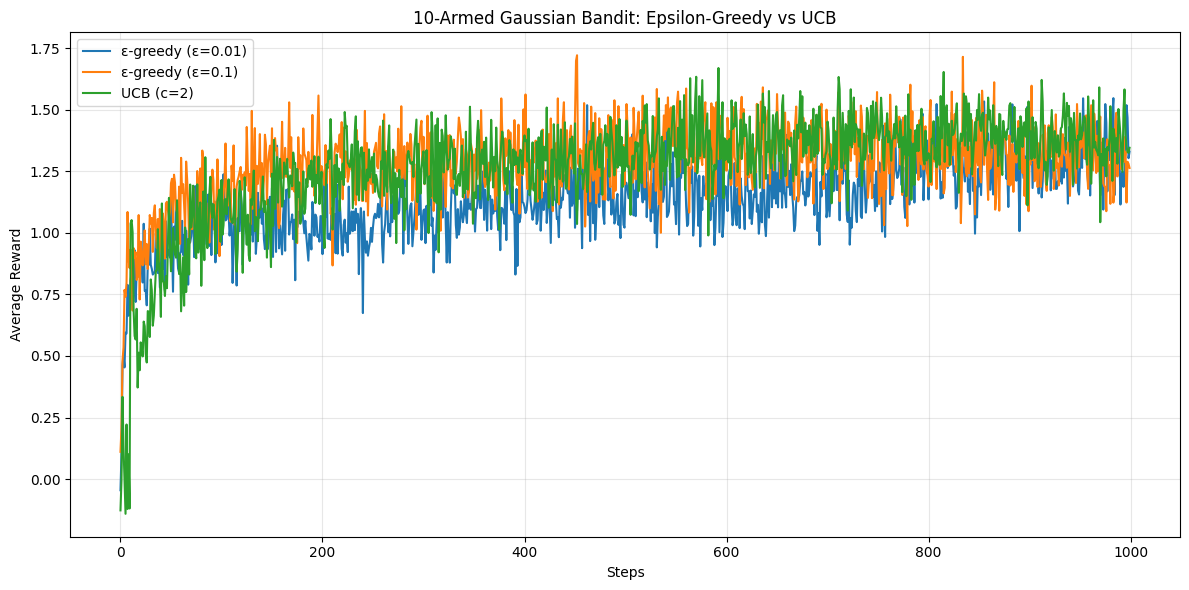

In [ ]:
# Plot average reward versus timestep

plt.figure(figsize=(12, 6))

for name, rewards in average_rewards.items():
    plt.plot(rewards, label=name)

plt.xlabel("Steps")
plt.ylabel("Average Reward")
plt.title(
    "10-Armed Gaussian Bandit: "
    "Epsilon-Greedy vs UCB"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Part 2: Plotting a Safe Course (MDPs and Dynamic Programming), 25 pts
#### Use FrozenLake-v1 (4×4, is_slippery=True) as a docking-bay hazard map. You may read the full transition model from env.unwrapped.P.
    1. Implement value iteration using the transition model. (12 pts)
    2. Extract the greedy policy and display both V and the policy as 4×4 grids. Evaluate the policy over 500 episodes and report its success rate.  (13 pts)

In [ ]:
!pip install gymnasium numpy matplotlib

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create the 4x4 FrozenLake environment
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

# Access the underlying environment and transition model
lake = env.unwrapped
P = lake.P

n_states = lake.observation_space.n
n_actions = lake.action_space.n

print("Number of states:", n_states)
print("Number of actions:", n_actions)

print("\nAction mapping:")
print("0 = Left, 1 = Down, 2 = Right, 3 = Up")

print("\nTransition model for state 0, action Down:")
print(P[0][1])

Number of states: 16
Number of actions: 4

Action mapping:
0 = Left, 1 = Down, 2 = Right, 3 = Up

Transition model for state 0, action Down:
[(0.3333333333333333, 0, 0.0, False), (0.3333333333333333, 4, 0.0, False), (0.3333333333333333, 1, 0.0, False)]


In [ ]:
# Implement value iteration

def value_iteration(P, n_states, n_actions,
                    gamma=0.99, theta=1e-10,
                    max_iterations=100000):

    # Initialize all state values to zero
    V = np.zeros(n_states)

    for iteration in range(max_iterations):
        delta = 0.0

        # Update each state's value
        for s in range(n_states):
            action_values = []

            # Calculate expected return for every action
            for a in range(n_actions):
                expected_return = 0.0

                for prob, next_state, reward, terminated in P[s][a]:

                    # Do not bootstrap beyond a terminal transition
                    continuation = (
                        0.0 if terminated else V[next_state]
                    )

                    expected_return += prob * (
                        reward + gamma * continuation
                    )

                action_values.append(expected_return)

            # Bellman optimality update
            new_value = max(action_values)

            delta = max(
                delta,
                abs(new_value - V[s])
            )

            V[s] = new_value

        # Stop when the value function converges
        if delta < theta:
            break

    else:
        raise RuntimeError(
            "Value iteration did not converge."
        )

    return V, iteration + 1


# Run value iteration
gamma = 0.99

V, num_iterations = value_iteration(
    P=P,
    n_states=n_states,
    n_actions=n_actions,
    gamma=gamma
)

print("Value iteration converged.")
print("Number of iterations:", num_iterations)
print("\nOptimal state-value function:")
print(V.reshape(4, 4))

Value iteration converged.
Number of iterations: 420

Optimal state-value function:
[[0.54202593 0.49880319 0.47069569 0.4568517 ]
 [0.55845096 0.         0.35834807 0.        ]
 [0.59179874 0.64307982 0.61520756 0.        ]
 [0.         0.74172044 0.86283743 0.        ]]


In [ ]:
# Extract the greedy policy

def extract_policy(P, V, n_states, n_actions,
                   gamma=0.99):

    policy = np.zeros(n_states, dtype=int)

    for s in range(n_states):
        action_values = np.zeros(n_actions)

        for a in range(n_actions):
            for prob, next_state, reward, terminated in P[s][a]:

                continuation = (
                    0.0 if terminated else V[next_state]
                )

                action_values[a] += prob * (
                    reward + gamma * continuation
                )

        # Select the greedy action
        policy[s] = np.argmax(action_values)

    return policy


policy = extract_policy(
    P=P,
    V=V,
    n_states=n_states,
    n_actions=n_actions,
    gamma=gamma
)

print("Greedy policy:")
print(policy.reshape(4, 4))

Greedy policy:
[[0 3 3 3]
 [0 0 0 0]
 [3 1 0 0]
 [0 2 1 0]]


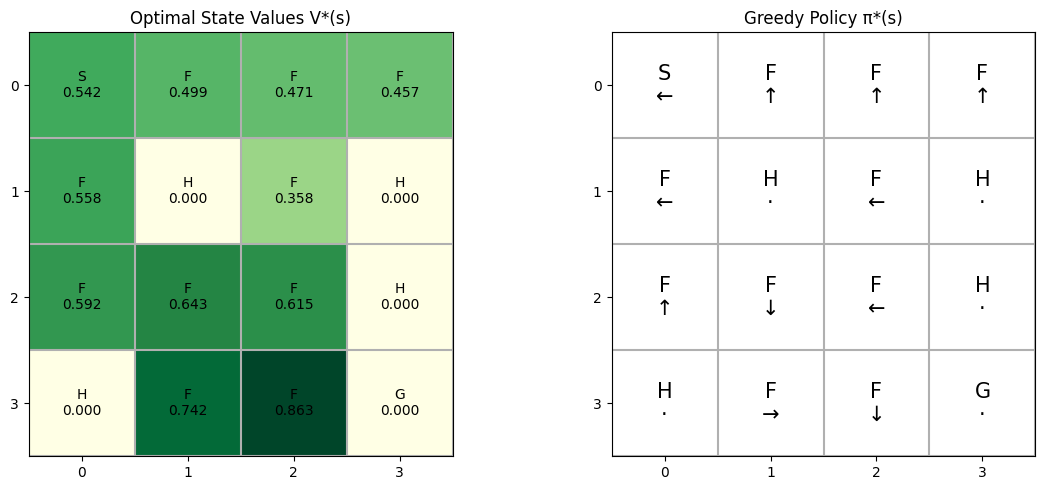

In [ ]:
# Display the value function and policy as 4×4 grids

# Read the lake layout
desc = lake.desc.astype("U1")

action_symbols = {
    0: "←",
    1: "↓",
    2: "→",
    3: "↑"
}

# Prepare the value and policy grids
value_grid = V.reshape(4, 4)

policy_grid = np.array([
    action_symbols[action]
    for action in policy
]).reshape(4, 4)

# Mark terminal tiles in the policy display
for s in range(n_states):
    row, col = divmod(s, 4)

    if desc[row, col] in ("H", "G"):
        policy_grid[row, col] = "·"


# Plot both grids
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# State-value function
axes[0].imshow(value_grid, cmap="YlGn", vmin=0)

axes[0].set_title("Optimal State Values V*(s)")
axes[0].set_xticks(range(4))
axes[0].set_yticks(range(4))

for row in range(4):
    for col in range(4):
        tile = desc[row, col]

        axes[0].text(
            col, row,
            f"{tile}\n{value_grid[row, col]:.3f}",
            ha="center",
            va="center",
            fontsize=10
        )

# Greedy policy
axes[1].imshow(
    np.zeros((4, 4)),
    cmap="Greys",
    vmin=0,
    vmax=1
)

axes[1].set_title("Greedy Policy π*(s)")
axes[1].set_xticks(range(4))
axes[1].set_yticks(range(4))

for row in range(4):
    for col in range(4):
        tile = desc[row, col]
        symbol = policy_grid[row, col]

        axes[1].text(
            col, row,
            f"{tile}\n{symbol}",
            ha="center",
            va="center",
            fontsize=15
        )

for ax in axes:
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    ax.grid(which="minor", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate the policy over 500 episodes

def evaluate_policy(env, policy, n_episodes=500,
                    seed=42):

    successes = 0
    episode_rewards = []

    for episode in range(n_episodes):
        state, info = env.reset(seed=seed + episode)

        total_reward = 0.0

        while True:
            # Follow the greedy policy
            action = int(policy[state])

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward

            # Stop at termination or time limit
            if terminated or truncated:
                break

        episode_rewards.append(total_reward)

        # FrozenLake gives reward 1 upon reaching the goal
        if total_reward > 0:
            successes += 1

    success_rate = 100.0 * successes / n_episodes
    average_reward = np.mean(episode_rewards)

    return success_rate, average_reward, successes


# Evaluate over 500 episodes
success_rate, average_reward, successes = evaluate_policy(
    env=env,
    policy=policy,
    n_episodes=500,
    seed=42
)

print("Policy Evaluation Results")
print("-------------------------")
print("Total episodes:", 500)
print("Successful episodes:", successes)
print(f"Success rate: {success_rate:.2f}%")
print(f"Average episode reward: {average_reward:.4f}")

env.close()

Policy Evaluation Results
-------------------------
Total episodes: 500
Successful episodes: 370
Success rate: 74.00%
Average episode reward: 0.7400


/home/cse/anaconda3/envs/py38_hasmita/lib/python3.8/site-packages/gymnasium/utils/passive_env_checker.py:249: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


# Part 3: Learning Without a Map (MC and TD Prediction), 20 pts
#### Mary no longer has the transition model. Use FrozenLake again, but do not access env.unwrapped.P.
    1. Implement first-visit Monte Carlo prediction for the policy from Part 2 (or a fixed heuristic policy if you prefer). (7 pts)
    2. Implement TD(0) prediction for the same policy. (7 pts)
    3. After 5,000 episodes, compute the mean squared error (MSE) between the estimated state values  and the true state values V^(s) obtained via Dynamic Programming in Part 2, and report the results across states in a concise comparison table.  (6 pts)

In [ ]:
import gymnasium as gym
import numpy as np
import pandas as pd

# Reference values from Part 2
V_true = np.asarray(V, dtype=float).copy()

# Fixed greedy policy from Part 2
fixed_policy = np.asarray(policy, dtype=int).copy()

N_STATES = 16
N_EPISODES = 5000
GAMMA = 0.99

assert V_true.shape == (N_STATES,)
assert fixed_policy.shape == (N_STATES,)

In [ ]:
# Same 4x4 slippery environment.
# Increase the time limit to reduce artificial truncation.
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True,
    max_episode_steps=10000
)

print("Environment ready.")
print("States:", N_STATES)
print("Episodes per method:", N_EPISODES)
print("Discount factor:", GAMMA)

Environment ready.
States: 16
Episodes per method: 5000
Discount factor: 0.99


In [ ]:
# First-visit Monte Carlo prediction

def first_visit_mc_prediction(
    env,
    policy,
    n_episodes=5000,
    gamma=0.99,
    seed=42
):
    n_states = env.observation_space.n

    V_mc = np.zeros(n_states)
    returns_sum = np.zeros(n_states)
    visit_count = np.zeros(n_states, dtype=int)

    truncated_episodes = 0

    for episode in range(n_episodes):
        state, info = env.reset(seed=seed + episode)

        states = []
        rewards = []

        # Generate an episode using the fixed policy
        while True:
            action = int(policy[state])

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            states.append(state)
            rewards.append(reward)

            state = next_state

            if terminated or truncated:
                if truncated:
                    truncated_episodes += 1
                break

        # Calculate returns backward
        returns = np.zeros(len(rewards))
        G = 0.0

        for t in reversed(range(len(rewards))):
            G = rewards[t] + gamma * G
            returns[t] = G

        # First-visit updates: traverse states forward
        visited = set()

        for t, state in enumerate(states):
            if state not in visited:
                visited.add(state)

                returns_sum[state] += returns[t]
                visit_count[state] += 1

                V_mc[state] = (
                    returns_sum[state] / visit_count[state]
                )

    return V_mc, visit_count, truncated_episodes


V_mc, mc_counts, mc_truncated = first_visit_mc_prediction(
    env=env,
    policy=fixed_policy,
    n_episodes=N_EPISODES,
    gamma=GAMMA,
    seed=42
)

print("First-visit MC prediction completed.")
print("Episodes:", N_EPISODES)
print("Episodes truncated:", mc_truncated)
print("\nMC estimated values:")
print(V_mc.reshape(4, 4))

/home/cse/anaconda3/envs/py38_hasmita/lib/python3.8/site-packages/gymnasium/utils/passive_env_checker.py:249: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


First-visit MC prediction completed.
Episodes: 5000
Episodes truncated: 0

MC estimated values:
[[0.53773507 0.50009813 0.47010633 0.46138369]
 [0.55428201 0.         0.35525972 0.        ]
 [0.58728395 0.63813347 0.60812366 0.        ]
 [0.         0.73970265 0.86357068 0.        ]]


In [ ]:
# TD(0) prediction

def td0_prediction(
    env,
    policy,
    n_episodes=5000,
    gamma=0.99,
    alpha=0.1,
    seed=10000
):
    n_states = env.observation_space.n

    V_td = np.zeros(n_states)
    visit_count = np.zeros(n_states, dtype=int)

    truncated_episodes = 0

    for episode in range(n_episodes):
        state, info = env.reset(seed=seed + episode)

        while True:
            action = int(policy[state])

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            visit_count[state] += 1

            # A true terminal transition has no continuation value.
            # A time-limit truncation is not a true terminal state.
            if terminated:
                target = reward
            else:
                target = reward + gamma * V_td[next_state]

            # TD(0) update
            V_td[state] += alpha * (
                target - V_td[state]
            )

            state = next_state

            if terminated or truncated:
                if truncated:
                    truncated_episodes += 1
                break

    return V_td, visit_count, truncated_episodes


V_td, td_counts, td_truncated = td0_prediction(
    env=env,
    policy=fixed_policy,
    n_episodes=N_EPISODES,
    gamma=GAMMA,
    alpha=0.1,
    seed=10000
)

print("TD(0) prediction completed.")
print("Episodes:", N_EPISODES)
print("Episodes truncated:", td_truncated)
print("\nTD(0) estimated values:")
print(V_td.reshape(4, 4))

TD(0) prediction completed.
Episodes: 5000
Episodes truncated: 0

TD(0) estimated values:
[[0.5364847  0.49532915 0.47509775 0.46272096]
 [0.54923515 0.         0.35315532 0.        ]
 [0.57709417 0.63709835 0.60194841 0.        ]
 [0.         0.76270608 0.88098495 0.        ]]


In [ ]:
# Compute MSE and compare the methods

mc_mse = np.mean((V_mc - V_true) ** 2)
td_mse = np.mean((V_td - V_true) ** 2)

comparison = pd.DataFrame({
    "Method": ["First-visit MC", "TD(0)"],
    "Episodes": [N_EPISODES, N_EPISODES],
    "Learning rate": ["Sample average", 0.1],
    "MSE": [mc_mse, td_mse]
})

print(comparison.to_string(index=False))

        Method  Episodes  Learning rate      MSE
First-visit MC      5000 Sample average 0.000010
         TD(0)      5000            0.1 0.000088


In [ ]:
# Compare the estimates state by state

state_comparison = pd.DataFrame({
    "State": np.arange(N_STATES),
    "V_DP": V_true,
    "V_MC": V_mc,
    "V_TD": V_td,
    "MC_Squared_Error": (V_mc - V_true) ** 2,
    "TD_Squared_Error": (V_td - V_true) ** 2,
    "MC_Visits": mc_counts,
    "TD_Visits": td_counts
})

print(
    state_comparison.round(5).to_string(index=False)
)

print("\nOverall MSE:")
print(f"First-visit MC: {mc_mse:.6f}")
print(f"TD(0):          {td_mse:.6f}")

 State    V_DP    V_MC    V_TD  MC_Squared_Error  TD_Squared_Error  MC_Visits  TD_Visits
     0 0.54203 0.53774 0.53648           0.00002           0.00003       5000      73297
     1 0.49880 0.50010 0.49533           0.00000           0.00001        756       2690
     2 0.47070 0.47011 0.47510           0.00000           0.00002        756       5258
     3 0.45685 0.46138 0.46272           0.00002           0.00003        522       5121
     4 0.55845 0.55428 0.54924           0.00002           0.00008       5000      56016
     5 0.00000 0.00000 0.00000           0.00000           0.00000          0          0
     6 0.35835 0.35526 0.35316           0.00001           0.00003       1902       2648
     7 0.00000 0.00000 0.00000           0.00000           0.00000          0          0
     8 0.59180 0.58728 0.57709           0.00002           0.00022       5000      39101
     9 0.64308 0.63813 0.63710           0.00002           0.00004       5000      21025
    10 0.61521 0.6081

In [ ]:
env.close()

# Part 4: Asteroid Field Navigation (SARSA vs. Q-learning), 30 pts
### Use CliffWalking-v0, where the cliff edge stands in for an asteroid belt.
    1. Implement tabular SARSA and Q-learning with ε-greedy exploration (, , ). Because this is an undiscounted episodic task (), ensure episodes terminate upon reaching the goal, or impose a maximum step cap per episode (e.g., 500 steps) during early exploration to prevent infinite wandering before convergence.  (12 pts)
    2. Train each for 300 episodes, averaged over 5 runs. Plot the smoothed reward per episode for both. (10 pts)
    3. Print each agent's final greedy path as a grid of arrows. (8 pts)

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Hyperparameters
ALPHA = 0.5
GAMMA = 1.0
EPSILON = 0.1

N_EPISODES = 300
N_RUNS = 5
MAX_STEPS = 500
SMOOTH_WINDOW = 10

env = gym.make("CliffWalking-v0")

N_STATES = env.observation_space.n
N_ACTIONS = env.action_space.n

print("States:", N_STATES)
print("Actions:", N_ACTIONS)

print("Action mapping:")
print("0 = Up, 1 = Right, 2 = Down, 3 = Left")

States: 48
Actions: 4
Action mapping:
0 = Up, 1 = Right, 2 = Down, 3 = Left


In [ ]:
# Implement ε-greedy exploration

def epsilon_greedy_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))

    # Randomly break ties among greedy actions
    best_actions = np.flatnonzero(
        np.isclose(Q[state], np.max(Q[state]))
    )

    return int(rng.choice(best_actions))

In [ ]:
# Implement SARSA

def train_sarsa(
    seed,
    n_episodes=300,
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1,
    max_steps=500
):
    rng = np.random.default_rng(seed)

    # Initialize action values
    Q = np.zeros((N_STATES, N_ACTIONS))

    episode_rewards = []
    episode_lengths = []

    for episode in range(n_episodes):
        state, info = env.reset(seed=seed + episode)

        action = epsilon_greedy_action(
            Q, state, epsilon, rng
        )

        total_reward = 0
        steps = 0

        for step in range(max_steps):
            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward
            steps += 1

            # Reaching the goal ends the episode
            if terminated:
                target = reward
                Q[state, action] += alpha * (
                    target - Q[state, action]
                )
                break

            # Select the next action using epsilon-greedy
            next_action = epsilon_greedy_action(
                Q, next_state, epsilon, rng
            )

            # SARSA update
            target = reward + gamma * Q[
                next_state, next_action
            ]

            Q[state, action] += alpha * (
                target - Q[state, action]
            )

            state = next_state
            action = next_action

        episode_rewards.append(total_reward)
        episode_lengths.append(steps)

    return (
        Q,
        np.array(episode_rewards),
        np.array(episode_lengths)
    )

In [ ]:
# Implement Q-learning

def train_q_learning(
    seed,
    n_episodes=300,
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1,
    max_steps=500
):
    rng = np.random.default_rng(seed)

    # Initialize action values
    Q = np.zeros((N_STATES, N_ACTIONS))

    episode_rewards = []
    episode_lengths = []

    for episode in range(n_episodes):
        state, info = env.reset(seed=seed + episode)

        total_reward = 0
        steps = 0

        for step in range(max_steps):
            action = epsilon_greedy_action(
                Q, state, epsilon, rng
            )

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward
            steps += 1

            # Terminal transitions have no future return
            if terminated:
                target = reward
            else:
                # Q-learning uses the maximum next-state value
                target = reward + gamma * np.max(
                    Q[next_state]
                )

            # Q-learning update
            Q[state, action] += alpha * (
                target - Q[state, action]
            )

            state = next_state

            if terminated or truncated:
                break

        episode_rewards.append(total_reward)
        episode_lengths.append(steps)

    return (
        Q,
        np.array(episode_rewards),
        np.array(episode_lengths)
    )

In [ ]:
# Train both algorithms over five independent runs

sarsa_rewards = np.zeros((N_RUNS, N_EPISODES))
q_learning_rewards = np.zeros((N_RUNS, N_EPISODES))

sarsa_lengths = np.zeros((N_RUNS, N_EPISODES))
q_learning_lengths = np.zeros((N_RUNS, N_EPISODES))

sarsa_Q_tables = []
q_learning_Q_tables = []

RUN_SEEDS = [42, 123, 456, 789, 2026]

for run in range(N_RUNS):
    seed = RUN_SEEDS[run]

    # Train SARSA
    Q_sarsa, rewards_sarsa, lengths_sarsa = train_sarsa(
        seed=seed,
        n_episodes=N_EPISODES,
        alpha=ALPHA,
        gamma=GAMMA,
        epsilon=EPSILON,
        max_steps=MAX_STEPS
    )

    sarsa_Q_tables.append(Q_sarsa)
    sarsa_rewards[run] = rewards_sarsa
    sarsa_lengths[run] = lengths_sarsa

    # Train Q-learning
    Q_q, rewards_q, lengths_q = train_q_learning(
        seed=seed,
        n_episodes=N_EPISODES,
        alpha=ALPHA,
        gamma=GAMMA,
        epsilon=EPSILON,
        max_steps=MAX_STEPS
    )

    q_learning_Q_tables.append(Q_q)
    q_learning_rewards[run] = rewards_q
    q_learning_lengths[run] = lengths_q

print("Training completed.")
print("SARSA runs:", len(sarsa_Q_tables))
print("Q-learning runs:", len(q_learning_Q_tables))

/home/cse/anaconda3/envs/py38_hasmita/lib/python3.8/site-packages/gymnasium/utils/passive_env_checker.py:249: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


Training completed.
SARSA runs: 5
Q-learning runs: 5


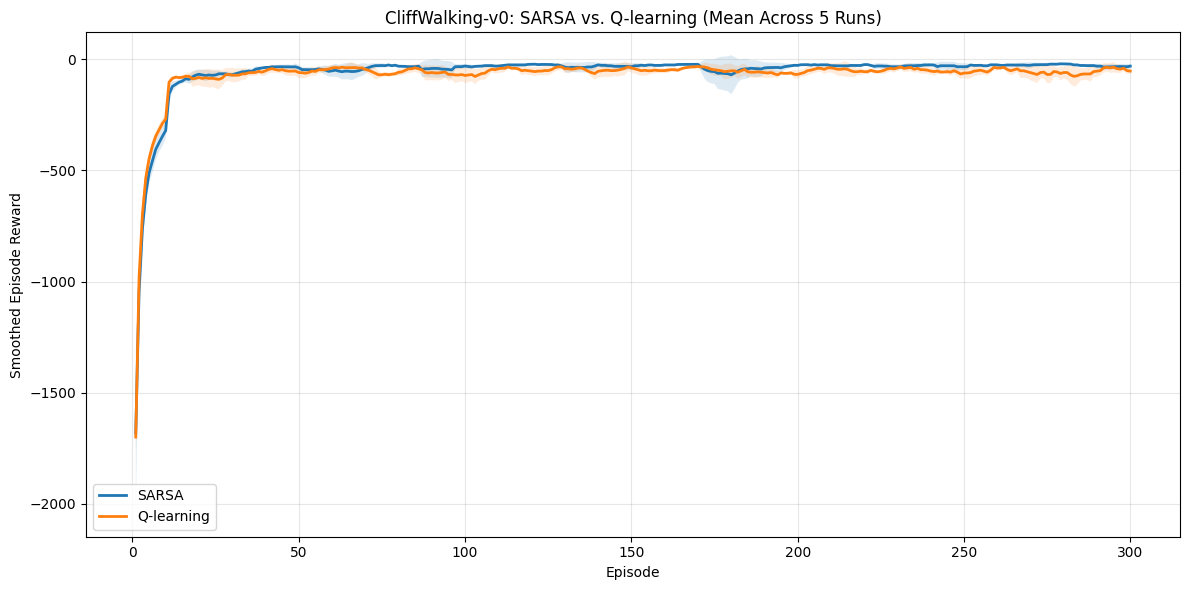

In [ ]:
# Plot smoothed reward per episode

def moving_average(data, window=10):
    smoothed = np.zeros_like(data, dtype=float)

    for i in range(len(data)):
        start = max(0, i - window + 1)
        smoothed[i] = np.mean(data[start:i + 1])

    return smoothed


# Smooth each run independently
sarsa_smoothed = np.array([
    moving_average(run_rewards, SMOOTH_WINDOW)
    for run_rewards in sarsa_rewards
])

q_smoothed = np.array([
    moving_average(run_rewards, SMOOTH_WINDOW)
    for run_rewards in q_learning_rewards
])

# Average smoothed rewards across the five runs
sarsa_mean = sarsa_smoothed.mean(axis=0)
q_mean = q_smoothed.mean(axis=0)

# Standard deviation across runs
sarsa_std = sarsa_smoothed.std(axis=0)
q_std = q_smoothed.std(axis=0)

episodes = np.arange(1, N_EPISODES + 1)

plt.figure(figsize=(12, 6))

plt.plot(
    episodes,
    sarsa_mean,
    label="SARSA",
    linewidth=2
)

plt.plot(
    episodes,
    q_mean,
    label="Q-learning",
    linewidth=2
)

# Show variability across runs
plt.fill_between(
    episodes,
    sarsa_mean - sarsa_std,
    sarsa_mean + sarsa_std,
    alpha=0.15
)

plt.fill_between(
    episodes,
    q_mean - q_std,
    q_mean + q_std,
    alpha=0.15
)

plt.xlabel("Episode")
plt.ylabel("Smoothed Episode Reward")
plt.title(
    "CliffWalking-v0: SARSA vs. Q-learning "
    "(Mean Across 5 Runs)"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Print each agent's final greedy path as a grid of arrows

# Average learned Q-tables across the five runs
Q_sarsa_mean = np.mean(sarsa_Q_tables, axis=0)
Q_q_mean = np.mean(q_learning_Q_tables, axis=0)

# Greedy action for each state
policy_sarsa = np.argmax(Q_sarsa_mean, axis=1)
policy_q = np.argmax(Q_q_mean, axis=1)

# CliffWalking-v0 is a 4x12 grid
N_ROWS = 4
N_COLS = 12

START_STATE = 36
GOAL_STATE = 47

ACTION_ARROWS = {
    0: "↑",
    1: "→",
    2: "↓",
    3: "←"
}

# Cliff cells: bottom row, columns 1 through 10
CLIFF_STATES = set(range(37, 47))


def trace_greedy_path(policy, max_steps=500):
    """Trace a deterministic greedy policy from start to goal."""

    state = START_STATE
    path = []
    visited = set()
    loop_state = None

    for _ in range(max_steps):
        if state == GOAL_STATE:
            break

        # Detect repeated states
        if state in visited:
            loop_state = state
            break

        visited.add(state)
        action = int(policy[state])
        path.append((state, action))

        # Simulate the intended grid movement deterministically
        row, col = divmod(state, N_COLS)

        if action == 0:       # Up
            row = max(0, row - 1)
        elif action == 1:     # Right
            col = min(N_COLS - 1, col + 1)
        elif action == 2:     # Down
            row = min(N_ROWS - 1, row + 1)
        elif action == 3:     # Left
            col = max(0, col - 1)

        next_state = row * N_COLS + col

        # Entering the cliff resets the agent to the start.
        # This is the deterministic intended-action visualization.
        if next_state in CLIFF_STATES:
            state = START_STATE
        else:
            state = next_state

    reached_goal = (state == GOAL_STATE)

    return path, reached_goal, loop_state


def print_path_grid(policy, agent_name):
    path, reached_goal, loop_state = trace_greedy_path(policy)

    # Start with an empty grid
    grid = np.full((N_ROWS, N_COLS), "·", dtype="<U2")

    # Mark the cliff
    for cliff_state in CLIFF_STATES:
        row, col = divmod(cliff_state, N_COLS)
        grid[row, col] = "C"

    # Mark arrows along the traced path
    for state, action in path:
        row, col = divmod(state, N_COLS)

        if state != START_STATE:
            grid[row, col] = ACTION_ARROWS[action]

    # Mark start and goal
    grid[3, 0] = "S"
    grid[3, 11] = "G"

    # Mark a loop if one was detected
    if loop_state is not None and loop_state != START_STATE:
        row, col = divmod(loop_state, N_COLS)
        grid[row, col] = "↻"

    print(f"\n{agent_name} Greedy Path")
    print("=" * 35)

    for row in grid:
        print(" ".join(row))

    print("Reached goal:", reached_goal)

    if loop_state is not None:
        print("Loop detected at state:", loop_state)

    print("Path transitions:", len(path))


print_path_grid(policy_sarsa, "SARSA")
print_path_grid(policy_q, "Q-learning")


SARSA Greedy Path
→ → → → → → → → → → → ↓
↑ · · · · · · · · · · ↓
↑ · · · · · · · · · · ↓
S C C C C C C C C C C G
Reached goal: True
Path transitions: 17

Q-learning Greedy Path
· · · · · · · · · · · ·
· · · · · · · · · · · ·
→ → → → → → → → → → → ↓
S C C C C C C C C C C G
Reached goal: True
Path transitions: 13


In [ ]:
# Compare final training performance numerically
last_50_sarsa = sarsa_rewards[:, -50:].mean(axis=1)
last_50_q = q_learning_rewards[:, -50:].mean(axis=1)

print("Performance over the last 50 episodes of each run")
print("------------------------------------------------")

print(
    f"SARSA:     {last_50_sarsa.mean():.2f} "
    f"+/- {last_50_sarsa.std(ddof=1):.2f}"
)

print(
    f"Q-learning: {last_50_q.mean():.2f} "
    f"+/- {last_50_q.std(ddof=1):.2f}"
)

Performance over the last 50 episodes of each run
------------------------------------------------
SARSA:     -26.36 +/- 5.49
Q-learning: -52.52 +/- 20.44


# Bonus: Mountain Pass Challenge (up to +10 pts)

Solve MountainCar-v0 using tile coding or a linear function approximator with semi-gradient SARSA. Plot the learning curve across 3 seeds. Full credit needs an agent that reaches the goal consistently. This part is optional and sits outside the 1-2 hour estimate.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

# Environment
ENV_NAME = "MountainCar-v0"

# Tile coding
NUM_TILINGS = 8
NUM_BINS = 8

# Semi-gradient SARSA
ALPHA = 0.3 / NUM_TILINGS
GAMMA = 1.0
EPSILON_START = 0.10
EPSILON_MIN = 0.01

# Training
NUM_EPISODES = 8000
NUM_SEEDS = 3
MAX_STEPS = 200
EVAL_EPISODES = 100

SEEDS = [42, 123, 456]

env = gym.make(ENV_NAME)

STATE_LOW = env.observation_space.low
STATE_HIGH = env.observation_space.high

N_ACTIONS = env.action_space.n

print("Environment:", ENV_NAME)
print("State space:", env.observation_space)
print("Action space:", env.action_space)
print("Number of actions:", N_ACTIONS)

env.close()

Environment: MountainCar-v0
State space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space: Discrete(3)
Number of actions: 3


In [ ]:
# Implement tile coding

class TileCoder:
    def __init__(
        self,
        state_low,
        state_high,
        num_tilings=8,
        num_bins=8
    ):
        self.state_low = np.asarray(state_low, dtype=float)
        self.state_high = np.asarray(state_high, dtype=float)

        self.num_tilings = num_tilings
        self.num_bins = num_bins

        # Extra boundary bin for shifted tilings
        self.bins_per_dimension = num_bins + 1

        self.tiles_per_tiling = (
            self.bins_per_dimension ** len(self.state_low)
        )

        self.num_features = (
            self.num_tilings * self.tiles_per_tiling
        )

    def encode(self, state):
        state = np.asarray(state, dtype=float)

        # Normalize position and velocity
        scaled = (
            (state - self.state_low)
            / (self.state_high - self.state_low)
        ) * self.num_bins

        active_features = []

        for tiling in range(self.num_tilings):
            # Shift each tiling to create overlapping features
            offset_position = tiling / self.num_tilings
            offset_velocity = (
                (tiling * 3) % self.num_tilings
            ) / self.num_tilings

            offsets = np.array([
                offset_position,
                offset_velocity
            ])

            coordinates = np.floor(scaled + offsets).astype(int)

            coordinates = np.clip(
                coordinates,
                0,
                self.bins_per_dimension - 1
            )

            position_bin, velocity_bin = coordinates

            local_index = (
                position_bin * self.bins_per_dimension
                + velocity_bin
            )

            global_index = (
                tiling * self.tiles_per_tiling
                + local_index
            )

            active_features.append(global_index)

        return np.asarray(active_features, dtype=int)

In [ ]:
# Implement semi-gradient SARSA

def epsilon_greedy_action(Q, active_features, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[0]))

    action_values = Q[:, active_features].sum(axis=1)

    # Randomly break ties between greedy actions
    best_actions = np.flatnonzero(
        np.isclose(action_values, action_values.max())
    )

    return int(rng.choice(best_actions))


def train_semi_gradient_sarsa(
    seed,
    num_episodes=NUM_EPISODES,
    alpha=ALPHA,
    gamma=GAMMA,
    epsilon_start=EPSILON_START,
    epsilon_min=EPSILON_MIN,
    max_steps=MAX_STEPS
):
    env = gym.make(ENV_NAME)

    rng = np.random.default_rng(seed)

    coder = TileCoder(
        env.observation_space.low,
        env.observation_space.high,
        num_tilings=NUM_TILINGS,
        num_bins=NUM_BINS
    )

    # One weight vector per action
    Q = np.zeros((env.action_space.n, coder.num_features))

    episode_returns = []
    episode_lengths = []
    episode_successes = []

    for episode in range(num_episodes):

        # Gradually reduce exploration
        fraction = min(episode / 4000.0, 1.0)

        epsilon = (
            epsilon_start
            + fraction * (epsilon_min - epsilon_start)
        )

        state, _ = env.reset(seed=seed + episode)
        active = coder.encode(state)

        action = epsilon_greedy_action(
            Q, active, epsilon, rng
        )

        total_reward = 0.0
        reached_goal = False

        for step in range(max_steps):

            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            next_active = coder.encode(next_state)

            # Terminal states have no future value
            if terminated:
                target = reward

                td_error = (
                    target - Q[action, active].sum()
                )

                Q[action, active] += alpha * td_error

                reached_goal = True
                total_reward += reward
                break

            # SARSA selects the next action using epsilon-greedy
            next_action = epsilon_greedy_action(
                Q, next_active, epsilon, rng
            )

            # Bootstrap unless the transition is terminal.
            # This also handles time-limit truncation.
            target = (
                reward
                + gamma * Q[next_action, next_active].sum()
            )

            td_error = (
                target - Q[action, active].sum()
            )

            # Semi-gradient update for active features
            Q[action, active] += alpha * td_error

            total_reward += reward

            if truncated:
                break

            state = next_state
            active = next_active
            action = next_action

        episode_returns.append(total_reward)
        episode_lengths.append(step + 1)
        episode_successes.append(reached_goal)

        if (episode + 1) % 1000 == 0:
            recent_success = np.mean(
                episode_successes[-100:]
            )

            print(
                f"Seed {seed} | "
                f"Episode {episode + 1}/{num_episodes} | "
                f"Recent success rate: {recent_success:.1%} | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    return (
        Q,
        coder,
        np.asarray(episode_returns),
        np.asarray(episode_lengths),
        np.asarray(episode_successes)
    )

In [ ]:
# Train across three random seeds

results = {}

for seed in SEEDS:
    print(f"\n{'=' * 55}")
    print(f"Training with seed {seed}")
    print(f"{'=' * 55}")

    Q, coder, returns, lengths, successes = (
        train_semi_gradient_sarsa(seed)
    )

    results[seed] = {
        "Q": Q,
        "coder": coder,
        "returns": returns,
        "lengths": lengths,
        "successes": successes
    }


Training with seed 42
Seed 42 | Episode 1000/8000 | Recent success rate: 100.0% | Epsilon: 0.078
Seed 42 | Episode 2000/8000 | Recent success rate: 99.0% | Epsilon: 0.055
Seed 42 | Episode 3000/8000 | Recent success rate: 100.0% | Epsilon: 0.033
Seed 42 | Episode 4000/8000 | Recent success rate: 100.0% | Epsilon: 0.010
Seed 42 | Episode 5000/8000 | Recent success rate: 100.0% | Epsilon: 0.010
Seed 42 | Episode 6000/8000 | Recent success rate: 100.0% | Epsilon: 0.010
Seed 42 | Episode 7000/8000 | Recent success rate: 100.0% | Epsilon: 0.010
Seed 42 | Episode 8000/8000 | Recent success rate: 100.0% | Epsilon: 0.010

Training with seed 123
Seed 123 | Episode 1000/8000 | Recent success rate: 100.0% | Epsilon: 0.078
Seed 123 | Episode 2000/8000 | Recent success rate: 100.0% | Epsilon: 0.055
Seed 123 | Episode 3000/8000 | Recent success rate: 100.0% | Epsilon: 0.033
Seed 123 | Episode 4000/8000 | Recent success rate: 100.0% | Epsilon: 0.010
Seed 123 | Episode 5000/8000 | Recent success rate

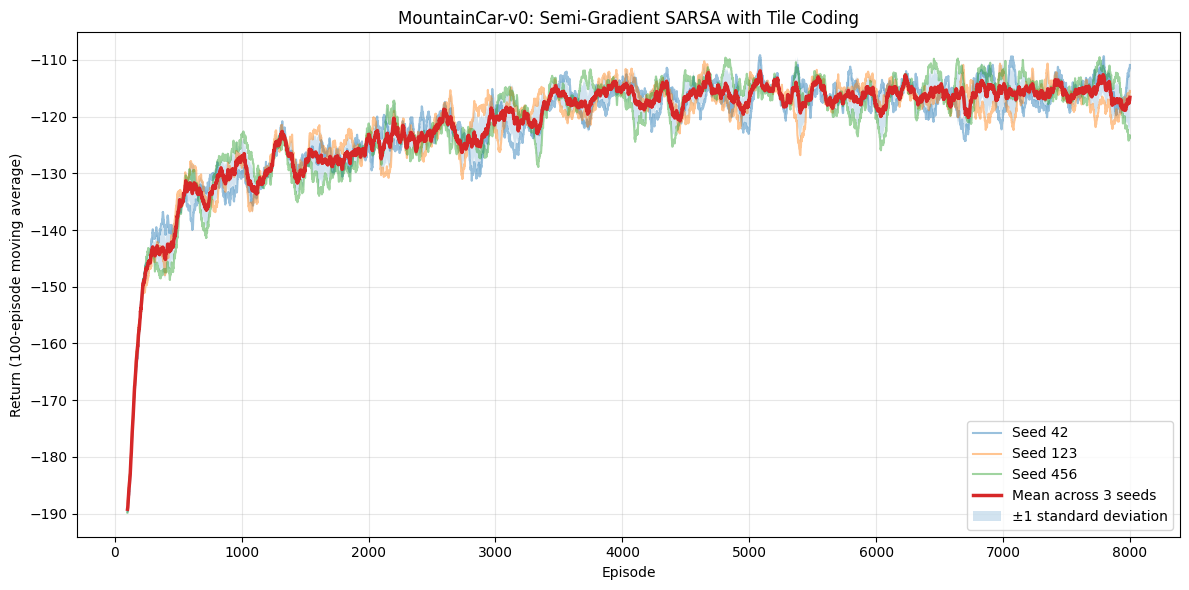

In [ ]:
# Plot the learning curve across three seeds

def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid"
    )


plt.figure(figsize=(12, 6))

smoothed_curves = []

for seed in SEEDS:
    curve = moving_average(
        results[seed]["returns"],
        window=100
    )

    smoothed_curves.append(curve)

    plt.plot(
        np.arange(100, NUM_EPISODES + 1),
        curve,
        alpha=0.45,
        label=f"Seed {seed}"
    )

smoothed_curves = np.asarray(smoothed_curves)

mean_curve = smoothed_curves.mean(axis=0)
std_curve = smoothed_curves.std(axis=0)

episodes = np.arange(100, NUM_EPISODES + 1)

plt.plot(
    episodes,
    mean_curve,
    linewidth=2.5,
    label="Mean across 3 seeds"
)

plt.fill_between(
    episodes,
    mean_curve - std_curve,
    mean_curve + std_curve,
    alpha=0.2,
    label="±1 standard deviation"
)

plt.xlabel("Episode")
plt.ylabel("Return (100-episode moving average)")
plt.title("MountainCar-v0: Semi-Gradient SARSA with Tile Coding")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Evaluate whether the agent reaches the goal

def evaluate_agent(Q, coder, seed, num_episodes=100):
    env = gym.make(ENV_NAME)

    episode_returns = []
    episode_lengths = []
    successes = 0

    for episode in range(num_episodes):
        state, _ = env.reset(seed=seed + 100_000 + episode)

        total_reward = 0.0

        for step in range(MAX_STEPS):
            active = coder.encode(state)

            # Greedy action selection: no exploration
            action_values = Q[:, active].sum(axis=1)
            action = int(np.argmax(action_values))

            state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            total_reward += reward

            if terminated:
                successes += 1
                break

            if truncated:
                break

        episode_returns.append(total_reward)
        episode_lengths.append(step + 1)

    env.close()

    return {
        "success_rate": successes / num_episodes,
        "mean_return": np.mean(episode_returns),
        "mean_length": np.mean(episode_lengths)
    }


evaluation_results = {}

print("\nFinal greedy-policy evaluation")
print("-" * 75)

for seed in SEEDS:
    result = evaluate_agent(
        results[seed]["Q"],
        results[seed]["coder"],
        seed=seed,
        num_episodes=EVAL_EPISODES
    )

    evaluation_results[seed] = result

    print(
        f"Seed {seed}: "
        f"Success rate = {result['success_rate']:.1%}, "
        f"Mean return = {result['mean_return']:.2f}, "
        f"Mean episode length = {result['mean_length']:.1f}"
    )

success_rates = [
    evaluation_results[seed]["success_rate"]
    for seed in SEEDS
]

print("-" * 75)
print(f"Mean success rate: {np.mean(success_rates):.1%}")
print(f"Std. dev. of success rate: {np.std(success_rates):.1%}")


Final greedy-policy evaluation
---------------------------------------------------------------------------
Seed 42: Success rate = 100.0%, Mean return = -123.55, Mean episode length = 123.5
Seed 123: Success rate = 100.0%, Mean return = -101.08, Mean episode length = 101.1
Seed 456: Success rate = 100.0%, Mean return = -111.01, Mean episode length = 111.0
---------------------------------------------------------------------------
Mean success rate: 100.0%
Std. dev. of success rate: 0.0%


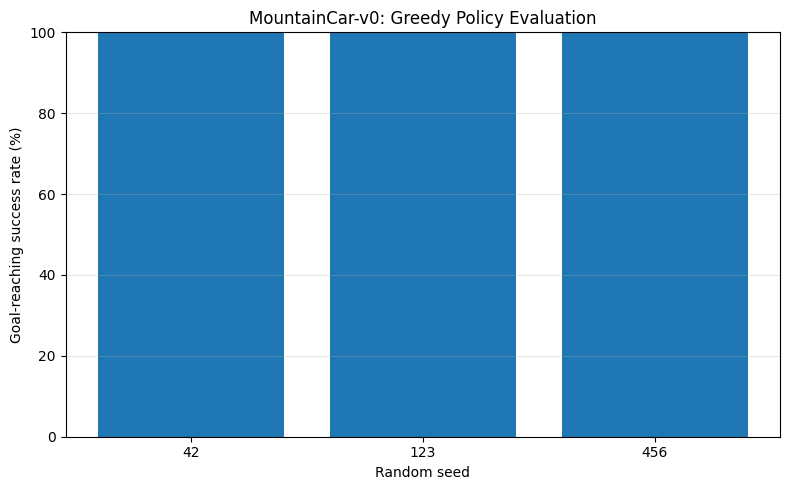

In [ ]:
# Plot evaluation success rates

plt.figure(figsize=(8, 5))

plt.bar(
    [str(seed) for seed in SEEDS],
    [100 * evaluation_results[seed]["success_rate"]
     for seed in SEEDS]
)

plt.xlabel("Random seed")
plt.ylabel("Goal-reaching success rate (%)")
plt.title("MountainCar-v0: Greedy Policy Evaluation")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()